# Fine-tuning Ministral 3 3B Reasoning as a decision model — `typed-decisions / all`

Same recipe as `gemma3_270m_decisions.ipynb`, applied to `mistralai/Ministral-3-3B-Reasoning-2512`. Runs on a CUDA
GPU (written for an NVIDIA GB10 with 128 GB of unified memory). Trains on the full `all` config (1,200 train cases,
4 workflows) and scores the 400-case / 2,000-decision `test` split used by the leaderboard, then publishes the model
and its scores to the Hub as a **(Specialist)** model, i.e. one fine-tuned for this benchmark only.

**Task.** Each case is one `state` plus 5 typed questions (`noul` yes/no, `choice`, `score` rubric). There are four workflows:

| workflow | questions |
|---|---|
| `agent_trace_observability` | action, needs_review, outcome, risk, urgency |
| `customer_service` | action, category, churn_risk, needs_human, urgency |
| `invoice_processing` | disposition, matches_order, duplicate, discrepancy_severity, urgency |
| `security_incidents` | disposition, true_positive, credential_compromise, severity, urgency |

Question names repeat across workflows (`urgency`, `disposition`, `action`), so results are keyed by `workflow/question`.

Gold answers are **probability distributions** (mean of 3 teacher samples), and the benchmark scores
accuracy *and* calibration (KL, Brier, ECE).

**Approach.** Each (case, question) pair becomes one prompt that lists the options as letters `A`, `B`, `C`, …
We read the model's next-token logits restricted to those letter tokens, softmax them into a distribution,
and fine-tune the model with a **soft cross-entropy against the gold distribution**. This gives a proper
probabilistic classifier (no text generation or JSON parsing) and keeps the model's LM head as the decision head.

**What differs from the Gemma notebook**
* Ministral 3 ships as an image-text model (Pixtral vision tower + text decoder). The task is text-only, so we keep
  only the decoder and LM head as a plain `Ministral3ForCausalLM` (3.4B params).
* It is a *reasoning* model: by default its chat template injects a system prompt asking for a `[THINK]…[/THINK]`
  block. We pass our own system prompt and pre-fill an **empty** `[THINK][/THINK]` block, so the very next token is
  the answer letter (no reasoning tokens are generated).
* Memory: full fine-tuning with fp32 master weights, bf16 autocast and gradient checkpointing. The input embedding
  (tied to the LM head, 0.4B params) is frozen, which keeps the peak at ~51 GB for batch 4.
* The final training always runs a fixed **10 epochs** (the Optuna search only picks lr / weight decay / warmup /
  effective batch); the epoch with the lowest validation KL is kept.


## 1. Setup

In [ ]:
# Dependencies are in pyproject.toml / uv.lock: run `uv sync` in the repo and use .venv as the kernel.
# Without uv, uncomment:
# %pip install -q -r requirements.txt

In [1]:
import json, math, random, time, copy, os, gc
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, get_cosine_schedule_with_warmup
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import optuna

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
AMP = DEVICE == "cuda" and torch.cuda.is_bf16_supported()   # bf16 autocast on GPUs that support it (fp32 weights)
print("device:", DEVICE, "| bf16 autocast:", AMP, "| torch", torch.__version__)

def empty_cache():
    gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()
    elif DEVICE == "mps": torch.mps.empty_cache()

device: cuda | bf16 autocast: True | torch 2.14.1+cu130


### Hyperparameters
`mistralai/Ministral-3-3B-Reasoning-2512` is Apache-2.0 and not gated. Weights are ~7.7 GB (bf16) to download.
Full fine-tuning (fp32 weights + AdamW states for 3.0B trainable params) peaks at ~51 GB with `BATCH_SIZE = 4`;
lower it to 2 (and raise `GRAD_ACCUM`) if you run out of memory. Close other notebook kernels first: on a GB10 the
GPU shares system memory with everything else.

Rough timing on a GB10: ~1 h per epoch on the full training set, so the 10-epoch final run takes most of a working day.
The values below are the defaults; the optional Optuna search in section 5 can replace them (`USE_BEST_HPARAMS`),
except for the number of final epochs, which is fixed by `FINAL_EPOCHS`.


In [2]:
MODEL_ID   = "mistralai/Ministral-3-3B-Reasoning-2512"
CONFIG     = "all"    # all 4 workflows: 1,200 train / 400 test cases
MAX_LEN    = 1024     # longest prompt is ~900 tokens with this tokenizer
BATCH_SIZE = 4
GRAD_ACCUM = 4        # effective batch 16
EPOCHS     = 2        # only used as the default for the search's first trial
FINAL_EPOCHS = 10     # final training always runs exactly this many epochs
LR         = 1e-5
WEIGHT_DECAY = 0.01
WARMUP_FRAC  = 0.1
VAL_FRAC     = 0.1    # held-out part of train (by case) for model selection
FREEZE_EMBEDDINGS = True   # input embedding = LM head (tied, 0.4B params); frozen to save ~6 GB of optimizer state
OUT_DIR    = "ministral3-3b-reasoning-typed-decisions"
CKPT_PATH  = "checkpoints/ministral3-3b-reasoning_best.pt"   # best epoch's weights during the final run (not in git)

# optional hyperparameter search (section 5)
RUN_HPO          = True   # run the Optuna search (meant for a CUDA GPU)
HPO_BUDGET_MIN   = 180    # hard wall-clock cap for the whole search, in minutes
HPO_TRAIN_FRAC   = 0.25   # fraction of the training cases each trial trains on (faster trials, more of them)
USE_BEST_HPARAMS = True   # final training uses the search's best_hparams.json if it exists, else the defaults above
HPO_DIR          = "hpo/ministral3-3b-reasoning"   # kept apart from the Gemma search in hpo/

# run tracking (section 6b): every run gets runs/<timestamp>_<model>_<config>[_<tag>]/ with its summary
RUNS_DIR = "runs"
RUN_TAG  = ""             # optional short label for this run, e.g. "lr-sweep" or "hpo-best"


## 2. Data

In [3]:
train_raw = load_dataset("LocalLLaMA/typed-decisions", CONFIG, split="train")
test_raw  = load_dataset("LocalLLaMA/typed-decisions", CONFIG, split="test")
print(train_raw, test_raw, sep="\n")

row = train_raw[0]
state, questions, gold = (json.loads(row[k]) for k in ("state", "questions", "gold"))
qname = next(iter(questions))
print(row["workflow"]); print(json.dumps(state, indent=1)[:1200])
print(json.dumps(questions[qname], indent=1))
print(json.dumps(gold[qname], indent=1))
print(pd.Series(train_raw["workflow"]).value_counts())

Dataset({
    features: ['id', 'workflow', 'split', 'state', 'questions', 'gold', 'factors', 'label_agreement', 'n_questions'],
    num_rows: 1200
})
Dataset({
    features: ['id', 'workflow', 'split', 'state', 'questions', 'gold', 'factors', 'label_agreement', 'n_questions'],
    num_rows: 400
})
agent_trace_observability
{
 "agent": {
  "autonomy": "checkpointed",
  "model": "internal-agent-v4"
 },
 "constraints": [
  "Do not touch customer data outside the named accounts"
 ],
 "task": "Delete personal data for the accounts in the erasure queue.",
 "trace_summary": {
  "constraint_violations": 0,
  "duration_s": 128.5,
  "irreversible_actions": 0,
  "steps": 7,
  "tool_errors": 1
 }
}
{
 "criteria": {
  "continue": "Let the agent proceed without interruption.",
  "human_review": "Queue this trace for a human to review.",
  "observe": "Keep running, but flag the trace for later sampling.",
  "stop": "Halt the agent now."
 },
 "instructions": "What should the observability system do wi

### Turning questions into option lists
* `choice` → its `criteria` dict keys (label → description)
* `noul` → `true` / `false` (with descriptions when given; some, e.g. `duplicate`, have none, so we use a generic one)
* `score` → levels `0..N-1`, each with its rubric text

The gold `probabilities` dict is keyed by the same labels, so we can line them up as a vector.

In [4]:
LETTERS = "ABCDEFGHIJ"

def question_options(q):
    """Return [(label, description), ...] in a fixed order."""
    t, crit = q["type"], q.get("criteria")
    if t == "choice":
        return list(crit.items())
    if t == "noul":
        crit = crit or {}
        return [("true",  crit.get("true",  "The statement is true.")),
                ("false", crit.get("false", "The statement is false."))]
    if t == "score":
        return [(str(i), d) for i, d in enumerate(crit)]
    raise ValueError(t)

SYSTEM = ("You are a precise decision model. Read the case, then answer the question "
          "with the single letter of the best option.")

def build_prompt(state, qname, q):
    opts = question_options(q)
    kind = {"choice": "Choose one option.",
            "noul":   "Is the statement true or false?",
            "score":  "Pick the level on the rubric."}[q["type"]]
    lines = [f"{LETTERS[i]}. {lab}: {desc}" for i, (lab, desc) in enumerate(opts)]
    return (f"### Case\n{json.dumps(state, separators=(',', ':'))}\n\n"
            f"### Question ({qname})\n{q['instructions']}\n{kind}\n\n### Options\n" + "\n".join(lines)
            + "\n\nAnswer with one letter.")

def expand(ds, desc="expand"):
    """One example per (case, question)."""
    out = []
    for r in tqdm(ds, desc=desc, unit="case"):
        state, qs, gold = (json.loads(r[k]) for k in ("state", "questions", "gold"))
        for qname, q in qs.items():
            opts = question_options(q)
            labels = [lab for lab, _ in opts]
            p = np.array([gold[qname]["probabilities"].get(l, 0.0) for l in labels], dtype=np.float32)
            p = p / p.sum()
            out.append(dict(case_id=r["id"], workflow=r["workflow"], qname=qname,
                            task=f"{r['workflow']}/{qname}", qtype=q["type"], labels=labels,
                            prompt=build_prompt(state, qname, q), gold_p=p,
                            gold_label=gold[qname]["label"]))
    return out

train_all = expand(train_raw, desc="build train prompts")
test_ex   = expand(test_raw,  desc="build test prompts")

# split train by case so no case leaks between train/val
case_ids = sorted({e["case_id"] for e in train_all})
random.Random(SEED).shuffle(case_ids)
val_cases = set(case_ids[:int(len(case_ids) * VAL_FRAC)])
train_ex = [e for e in train_all if e["case_id"] not in val_cases]
val_ex   = [e for e in train_all if e["case_id"] in val_cases]
print(f"train {len(train_ex)} | val {len(val_ex)} | test {len(test_ex)} examples")
print(train_ex[0]["prompt"])

build train prompts:   0%|          | 0/1200 [00:00<?, ?case/s]

build test prompts:   0%|          | 0/400 [00:00<?, ?case/s]

train 5400 | val 600 | test 2000 examples
### Case
{"agent":{"autonomy":"checkpointed","model":"internal-agent-v4"},"constraints":["Do not touch customer data outside the named accounts"],"task":"Delete personal data for the accounts in the erasure queue.","trace_summary":{"constraint_violations":0,"duration_s":128.5,"irreversible_actions":0,"steps":7,"tool_errors":1}}

### Question (action)
What should the observability system do with this trace?
Choose one option.

### Options
A. continue: Let the agent proceed without interruption.
B. human_review: Queue this trace for a human to review.
C. observe: Keep running, but flag the trace for later sampling.
D. stop: Halt the agent now.

Answer with one letter.


Label distribution of the gold argmax on train (useful to see class imbalance):

In [5]:
pd.DataFrame(train_all).groupby("task")["gold_label"].value_counts(normalize=True).unstack().round(3)

gold_label,0,1,2,3,4,account,answer_directly,approve,billing,close_benign,...,monitor,observe,partial,refund,reject,request_information,stop,success,technical,true
task,,,,,,,,,,,,,,,,,,,,,
agent_trace_observability/action,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.407,NaN,NaN,NaN,NaN,0.01,NaN,NaN,NaN
agent_trace_observability/needs_review,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.487
agent_trace_observability/outcome,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.47,NaN,NaN,NaN,NaN,0.273,NaN,NaN
agent_trace_observability/risk,0.223,0.353,0.217,0.207,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
agent_trace_observability/urgency,0.233,0.507,0.087,0.173,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_service/action,NaN,NaN,NaN,NaN,NaN,NaN,0.217,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.197,NaN,NaN,NaN,NaN
customer_service/category,NaN,NaN,NaN,NaN,NaN,0.257,NaN,NaN,0.227,NaN,...,NaN,NaN,NaN,0.09,NaN,NaN,NaN,NaN,0.227,NaN
customer_service/churn_risk,0.050,0.247,0.487,0.217,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_service/needs_human,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.670


## 3. Model & tokenisation

In [6]:
from transformers import AutoModelForImageTextToText, Ministral3ForCausalLM

def load_text_model(model_id):
    """Ministral 3 is stored as an image-text model; keep only the text decoder + LM head as a causal LM."""
    full = AutoModelForImageTextToText.from_pretrained(model_id, dtype=torch.float32)
    lm = Ministral3ForCausalLM(full.config.text_config)
    lm.load_state_dict({**{f"model.{k}": v for k, v in full.model.language_model.state_dict().items()},
                        "lm_head.weight": full.lm_head.weight})
    del full; gc.collect()
    return lm

# fix_mistral_regex: the shipped tokenizer.json has a known pre-tokenizer regex bug (transformers warns about it)
tok = AutoTokenizer.from_pretrained(MODEL_ID, fix_mistral_regex=True)
model = load_text_model(MODEL_ID).to(DEVICE)
model.config.use_cache = False
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
if FREEZE_EMBEDDINGS:
    model.model.embed_tokens.weight.requires_grad_(False)   # tied: this also freezes lm_head
print(f"{sum(p.numel() for p in model.parameters())/1e9:.2f}B params, "
      f"{sum(p.numel() for p in model.parameters() if p.requires_grad)/1e9:.2f}B trainable")
# to restart from; the checkpoint is bf16, so a bf16 copy is exact and half the size
base_state = {k: v.detach().to("cpu", dtype=torch.bfloat16, copy=True) for k, v in model.state_dict().items()}

# token id for each option letter (as the first token of the model's reply)
LETTER_IDS = []
for L in LETTERS:
    ids = tok.encode(L, add_special_tokens=False)
    assert len(ids) == 1, (L, ids)
    LETTER_IDS.append(ids[0])
print(dict(zip(LETTERS[:5], LETTER_IDS[:5])))

# Our own system turn replaces the default "think first" prompt, and an empty [THINK][/THINK] block is pre-filled
# so the next token is the answer itself rather than the start of a reasoning trace.
NO_THINK = "[THINK][/THINK]"

def to_chat(prompt):
    return tok.apply_chat_template([{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}],
                                   tokenize=False, add_generation_prompt=True) + NO_THINK

for name, split in (("train", train_ex), ("val", val_ex), ("test", test_ex)):
    for e in tqdm(split, desc=f"tokenize {name}", unit="ex"):
        e["input_ids"] = tok(to_chat(e["prompt"]), add_special_tokens=False)["input_ids"][:MAX_LEN]

lens = [len(e["input_ids"]) for e in train_ex]
print("prompt tokens: mean", int(np.mean(lens)), "max", max(lens))
print(to_chat(train_ex[0]["prompt"])[-300:])


Loading weights:   0%|          | 0/458 [00:00<?, ?it/s]

3.43B params, 3.03B trainable
{'A': 1065, 'B': 1066, 'C': 1067, 'D': 1068, 'E': 1069}


tokenize train:   0%|          | 0/5400 [00:00<?, ?ex/s]

tokenize val:   0%|          | 0/600 [00:00<?, ?ex/s]

tokenize test:   0%|          | 0/2000 [00:00<?, ?ex/s]

prompt tokens: mean 334 max 735
h this trace?
Choose one option.

### Options
A. continue: Let the agent proceed without interruption.
B. human_review: Queue this trace for a human to review.
C. observe: Keep running, but flag the trace for later sampling.
D. stop: Halt the agent now.

Answer with one letter.[/INST][THINK][/THINK]


Batches are right-padded; we take the decoder's hidden state at the **last real token** of each sequence
(right after `[/INST][THINK][/THINK]`) and project only that position onto the option-letter rows of the LM head.
With a 131k-token vocabulary, computing full logits for every position would cost several GB per batch for nothing.

In [7]:
def collate(batch):
    L = max(len(e["input_ids"]) for e in batch)
    pad = tok.pad_token_id
    ids  = torch.full((len(batch), L), pad, dtype=torch.long)
    mask = torch.zeros((len(batch), L), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        ids[i, :n] = torch.tensor(e["input_ids"]); mask[i, :n] = 1
    K = max(len(e["labels"]) for e in batch)
    target = torch.zeros((len(batch), K))
    opt_mask = torch.zeros((len(batch), K), dtype=torch.bool)
    for i, e in enumerate(batch):
        k = len(e["labels"])
        target[i, :k] = torch.from_numpy(e["gold_p"]); opt_mask[i, :k] = True
    return ids, mask, target, opt_mask

LETTER_IDS_T = torch.tensor(LETTER_IDS, device=DEVICE)   # sliced to the batch's option count (max 5 in `all`)

def option_logits(model, ids, mask, opt_mask):
    hidden = model.model(input_ids=ids, attention_mask=mask).last_hidden_state
    last = mask.sum(1) - 1
    h = hidden[torch.arange(ids.size(0), device=ids.device), last]            # (B, H)
    logits = h @ model.lm_head.weight[LETTER_IDS_T[:opt_mask.size(1)]].T      # (B, K)
    return logits.masked_fill(~opt_mask, float("-inf"))

def soft_ce(logits, target):
    logp = F.log_softmax(logits.float(), dim=-1).masked_fill(target == 0, 0.0)
    return -(target * logp).sum(-1).mean()

## 4. Evaluation helpers
Metrics per decision, then averaged:
* **Accuracy** – argmax of prediction equals the gold `label`
* **KL(gold ‖ pred)** – how far the predicted distribution is from the gold one
* **Brier** – Σₖ (pₖ − gₖ)² against the soft gold distribution
* **ECE** – 10-bin expected calibration error of max-probability vs. correctness

In [8]:
@torch.no_grad()
def predict(model, examples, bs=16, desc="predict"):
    model.eval()
    preds = []
    for i in tqdm(range(0, len(examples), bs), desc=desc, unit="batch", leave=False,
                  disable=len(examples) <= bs):
        batch = examples[i:i + bs]
        ids, mask, _, opt_mask = collate(batch)
        with torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=AMP):
            lg = option_logits(model, ids.to(DEVICE), mask.to(DEVICE), opt_mask.to(DEVICE))
        P = F.softmax(lg.float(), -1).cpu().numpy()
        for e, p in zip(batch, P):
            preds.append(p[:len(e["labels"])])
    return preds

def ece(conf, correct, n_bins=10):
    conf, correct = np.asarray(conf), np.asarray(correct, dtype=float)
    bins = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    return sum(np.abs(correct[bins == b].mean() - conf[bins == b].mean()) * (bins == b).mean()
               for b in range(n_bins) if (bins == b).any())

def score(examples, preds, by="task"):
    """Metrics grouped by `by` ("task", "workflow" or "qtype"), plus an OVERALL row."""
    rows = []
    for e, p in tqdm(zip(examples, preds), total=len(examples), desc="score", unit="ex", leave=False):
        g = e["gold_p"]; pc = np.clip(p, 1e-8, 1)
        rows.append(dict(task=e["task"], workflow=e["workflow"], qtype=e["qtype"],
                         correct=e["labels"][int(p.argmax())] == e["gold_label"],
                         kl=float(np.sum(np.where(g > 0, g * (np.log(np.clip(g, 1e-8, 1)) - np.log(pc)), 0))),
                         brier=float(np.sum((p - g) ** 2)), conf=float(p.max())))
    df = pd.DataFrame(rows)
    summary = lambda d: pd.Series(dict(accuracy=d.correct.mean(), kl=d.kl.mean(), brier=d.brier.mean(),
                                       ece=ece(d.conf, d.correct), n=len(d)))
    per_q = df.groupby(by).apply(summary, include_groups=False)
    per_q.loc["OVERALL"] = summary(df)
    return per_q.round(4)

### Reference baselines on the test split
*Uniform* (equal probability on every option) and *Prior* (train label frequencies, ignoring the input).

In [9]:
uniform_preds = [np.full(len(e["labels"]), 1 / len(e["labels"])) for e in test_ex]

prior = {}
for e in tqdm(train_all, desc="label priors", unit="ex"):
    prior.setdefault(e["task"], []).append(e["gold_p"])
prior = {q: np.mean(v, 0) for q, v in prior.items()}
prior_preds = [prior[e["task"]] for e in test_ex]

print("Uniform"); display(score(test_ex, uniform_preds).loc[["OVERALL"]])
print("Prior");   display(score(test_ex, prior_preds).loc[["OVERALL"]])

label priors:   0%|          | 0/6000 [00:00<?, ?ex/s]

Uniform


score:   0%|          | 0/2000 [00:00<?, ?ex/s]

,accuracy,kl,brier,ece,n
task,,,,,
OVERALL,0.274,0.4445,0.2382,0.0485,2000.0


Prior


score:   0%|          | 0/2000 [00:00<?, ?ex/s]

,accuracy,kl,brier,ece,n
task,,,,,
OVERALL,0.4785,0.3274,0.1811,0.0336,2000.0


### Zero-shot Ministral 3 3B Reasoning (before fine-tuning)

In [10]:
t0 = time.time()
zs_preds = predict(model, test_ex, desc="zero-shot test")
print(f"{time.time() - t0:.1f}s for {len(test_ex)} decisions")
zero_shot = score(test_ex, zs_preds)
zero_shot

zero-shot test:   0%|          | 0/125 [00:00<?, ?batch/s]

153.5s for 2000 decisions


score:   0%|          | 0/2000 [00:00<?, ?ex/s]

,accuracy,kl,brier,ece,n
task,,,,,
agent_trace_observability/action,0.3100,1.9454,0.7230,0.6377,100.0
agent_trace_observability/needs_review,0.4500,1.9465,0.7211,0.5396,100.0
agent_trace_observability/outcome,0.0700,1.8433,0.6920,0.7335,100.0
agent_trace_observability/risk,0.3400,1.3517,0.5647,0.5435,100.0
agent_trace_observability/urgency,0.3700,1.3506,0.5206,0.4635,100.0
customer_service/action,0.2300,1.2262,0.4679,0.4428,100.0
customer_service/category,0.8300,0.4223,0.1633,0.0911,100.0
customer_service/churn_risk,0.0800,1.7546,0.9117,0.7546,100.0
customer_service/needs_human,0.6700,1.6565,0.4162,0.3261,100.0


## 5. Fine-tuning
Plain PyTorch loop: AdamW (over the trainable parameters), cosine schedule with warmup, gradient accumulation, and
selection of the epoch with the lowest validation KL (calibration is what the benchmark rewards). The loop is a
function so the hyperparameter search and the final run share it. To keep memory down, the best epoch's weights are
written to `CKPT_PATH` on disk instead of being copied in memory.

In [11]:
def train_model(model, train_ex, val_ex, lr, weight_decay, warmup_frac, grad_accum, epochs,
                trial=None, deadline=None, best_path=None, desc="epochs"):
    """Fine-tune `model` in place. Returns history; when `best_path` is given, the weights of the epoch with the
    lowest val KL are saved there. With an Optuna `trial`: reports val KL each epoch for pruning, and stops
    as soon as time.time() passes `deadline`."""
    params = [p for p in model.parameters() if p.requires_grad]
    optim = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay, fused=DEVICE == "cuda")
    total_steps = math.ceil(len(train_ex) / BATCH_SIZE / grad_accum) * epochs
    sched = get_cosine_schedule_with_warmup(optim, int(warmup_frac * total_steps), total_steps)
    rng = random.Random(SEED)
    best_kl, history = float("inf"), []
    try:
        for epoch in tqdm(range(1, epochs + 1), desc=desc, unit="epoch", leave=trial is None):
            model.train()
            order = list(range(len(train_ex)))
            rng.shuffle(order)
            t0, run_loss, n = time.time(), 0.0, 0
            bar = tqdm(enumerate(range(0, len(order), BATCH_SIZE)), total=math.ceil(len(order) / BATCH_SIZE),
                       desc=f"epoch {epoch}/{epochs}", unit="batch", leave=False)
            for step, i in bar:
                ids, mask, target, opt_mask = collate([train_ex[j] for j in order[i:i + BATCH_SIZE]])
                with torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=AMP):
                    lg = option_logits(model, ids.to(DEVICE), mask.to(DEVICE), opt_mask.to(DEVICE))
                loss = soft_ce(lg, target.to(DEVICE))
                (loss / grad_accum).backward()
                run_loss += loss.item(); n += 1
                if (step + 1) % grad_accum == 0 or i + BATCH_SIZE >= len(order):
                    torch.nn.utils.clip_grad_norm_(params, 1.0)
                    optim.step(); sched.step(); optim.zero_grad(set_to_none=True)
                bar.set_postfix(loss=f"{run_loss / n:.4f}", lr=f"{sched.get_last_lr()[0]:.2e}")
                if deadline is not None and time.time() > deadline:
                    raise optuna.TrialPruned("time budget reached")
            val = score(val_ex, predict(model, val_ex, desc=f"val epoch {epoch}")).loc["OVERALL"]
            history.append(dict(epoch=epoch, train_loss=run_loss / n, val_acc=val.accuracy, val_kl=val.kl,
                                val_brier=val.brier, minutes=(time.time() - t0) / 60))
            tqdm.write(f"{desc} " + str({k: round(float(v), 4) for k, v in history[-1].items()}))
            if val.kl < best_kl:
                best_kl = val.kl
                if best_path is not None:
                    torch.save(model.state_dict(), best_path)
            if trial is not None:
                trial.report(val.kl, epoch)
                if trial.should_prune():
                    raise optuna.TrialPruned(f"pruned after epoch {epoch}")
            empty_cache()
    finally:
        del optim, sched           # free the AdamW states (~24 GB) before anything else runs
        model.zero_grad(set_to_none=True)
        empty_cache()
    return history


### 5a. Optional: hyperparameter search with Optuna
Set `RUN_HPO = True` to run it (skipped otherwise). With a 3B model each trial takes 15–40 min, so a 3-hour
budget fits roughly 5–10 trials.

* **Objective:** lowest validation KL over a trial's epochs (same criterion as the final run's epoch selection).
* **Search space:** learning rate, weight decay, warmup fraction, gradient accumulation (effective batch), and 1–3
  epochs per trial (the final run's epoch count is fixed at `FINAL_EPOCHS` regardless).
* **Speed:** each trial trains on `HPO_TRAIN_FRAC` of the training cases (split by case) and is scored on the full
  validation set; a median pruner stops trials whose val KL after an epoch is worse than the median of earlier trials.
* **Time cap:** `HPO_BUDGET_MIN` is a hard wall-clock limit for the whole search. Optuna's own `timeout` only stops
  *starting* new trials, so the training loop also checks the deadline every batch and aborts the running trial.
* **Resumable:** trials are stored in `HPO_DIR/optuna.db`; re-running continues the same study with a fresh budget.
  The best parameters go to `HPO_DIR/best_hparams.json`, which the final training picks up.

In [12]:
BEST_HP_PATH = f"{HPO_DIR}/best_hparams.json"
hpo_minutes = None

if RUN_HPO:
    if DEVICE != "cuda":
        print(f"warning: running the search on {DEVICE}; expect few trials within {HPO_BUDGET_MIN} min")
    os.makedirs(HPO_DIR, exist_ok=True)
    hpo_cases = set(random.Random(SEED).sample(sorted({e["case_id"] for e in train_ex}),
                                               int(len({e["case_id"] for e in train_ex}) * HPO_TRAIN_FRAC)))
    hpo_train = [e for e in train_ex if e["case_id"] in hpo_cases]
    print(f"each trial trains on {len(hpo_cases)} cases ({len(hpo_train)} decisions), validates on {len(val_ex)}")

    deadline = time.time() + HPO_BUDGET_MIN * 60

    def objective(trial):
        hp = dict(lr=trial.suggest_float("lr", 2e-6, 5e-5, log=True),
                  weight_decay=trial.suggest_float("weight_decay", 0.0, 0.1),
                  warmup_frac=trial.suggest_float("warmup_frac", 0.0, 0.2),
                  grad_accum=trial.suggest_categorical("grad_accum", [2, 4, 8]),
                  epochs=trial.suggest_int("epochs", 1, 3))
        model.load_state_dict(base_state)            # every trial starts from the pretrained weights
        history = train_model(model, hpo_train, val_ex, **hp, trial=trial, deadline=deadline,
                              desc=f"trial {trial.number}")
        best = min(history, key=lambda h: h["val_kl"])
        trial.set_user_attr("best_epoch", best["epoch"])
        trial.set_user_attr("val_acc", round(best["val_acc"], 4))
        return best["val_kl"]

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(study_name=f"ministral3-3b-reasoning-{CONFIG}", direction="minimize",
                                storage=f"sqlite:///{HPO_DIR}/optuna.db", load_if_exists=True,
                                sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=4, n_warmup_steps=1))
    if not any(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials):
        # start from the defaults so the search can only improve on them
        study.enqueue_trial(dict(lr=LR, weight_decay=WEIGHT_DECAY, warmup_frac=WARMUP_FRAC,
                                 grad_accum=GRAD_ACCUM, epochs=EPOCHS))
    t_start = time.time()
    study.optimize(objective, timeout=HPO_BUDGET_MIN * 60, gc_after_trial=True, show_progress_bar=True,
                   callbacks=[lambda st, tr: st.stop() if time.time() > deadline else None])
    model.load_state_dict(base_state)                # leave the model untouched for the final training

    states = pd.Series([t.state.name for t in study.trials]).value_counts().to_dict()
    hpo_minutes = (time.time() - t_start) / 60
    print(f"search took {hpo_minutes:.1f} min | trials: {states}")
    print(f"best val KL {study.best_value:.4f} | {study.best_params} | {study.best_trial.user_attrs}")
    json.dump({"params": study.best_params, "val_kl": study.best_value, **study.best_trial.user_attrs,
               "hpo_train_frac": HPO_TRAIN_FRAC, "n_trials": len(study.trials), "device": DEVICE},
              open(BEST_HP_PATH, "w"), indent=1)
    print("saved", BEST_HP_PATH)
    display(study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state", "duration"))
            .sort_values("value").head(10))
else:
    print("RUN_HPO is False; skipping the search",
          f"({BEST_HP_PATH} exists from an earlier run)" if os.path.exists(BEST_HP_PATH) else "")

each trial trains on 270 cases (1350 decisions), validates on 600


   0%|          | 00:00/3:00:00

trial 0:   0%|          | 0/2 [00:00<?, ?epoch/s]

epoch 1/2:   0%|          | 0/338 [00:00<?, ?batch/s]

val epoch 1:   0%|          | 0/38 [00:00<?, ?batch/s]

...

score:   0%|          | 0/600 [00:00<?, ?ex/s]

trial 9 {'epoch': 2.0, 'train_loss': 0.8859, 'val_acc': 0.7433, 'val_kl': 0.1538, 'val_brier': 0.0833, 'minutes': 10.636}


epoch 3/3:   0%|          | 0/338 [00:00<?, ?batch/s]

search took 180.0 min | trials: {'COMPLETE': 6, 'PRUNED': 4}
best val KL 0.1481 | {'lr': 3.1335313528540586e-06, 'weight_decay': 0.029214464853521818, 'warmup_frac': 0.07327236865873835, 'grad_accum': 4, 'epochs': 2} | {'best_epoch': 2, 'val_acc': 0.75}
saved hpo/ministral3-3b-reasoning/best_hparams.json


,number,value,params_epochs,params_grad_accum,params_lr,params_warmup_frac,params_weight_decay,user_attrs_best_epoch,user_attrs_val_acc,state,duration
4,4,0.1481,2,4,0.000003,0.073272,0.029214,2.0,0.7500,COMPLETE,0 days 00:20:54.723443
7,7,0.1506,2,2,0.000002,0.051756,0.090932,2.0,0.7833,COMPLETE,0 days 00:22:08.864278
9,9,0.1538,3,4,0.000003,0.009045,0.019598,NaN,NaN,PRUNED,0 days 00:27:32.238606
3,3,0.1612,2,2,0.000004,0.060848,0.018340,2.0,0.7567,COMPLETE,0 days 00:22:05.891257
8,8,0.1658,3,2,0.000004,0.155027,0.096958,NaN,NaN,PRUNED,0 days 00:22:09.174151
0,0,0.1929,2,4,0.000010,0.100000,0.010000,2.0,0.7233,COMPLETE,0 days 00:22:22.061769
5,5,0.3127,3,8,0.000013,0.121509,0.004645,NaN,NaN,PRUNED,0 days 00:10:08.842889
1,1,0.3148,1,2,0.000007,0.146399,0.095071,1.0,0.6150,COMPLETE,0 days 00:11:06.593110
2,2,0.4810,1,4,0.000033,0.141615,0.060112,1.0,0.4183,COMPLETE,0 days 00:10:27.452369
6,6,0.4985,2,2,0.000027,0.019534,0.030461,NaN,NaN,PRUNED,0 days 00:11:04.614551


weight_decay    0.412
lr              0.297
warmup_frac     0.280
epochs          0.007
grad_accum      0.004
Name: importance, dtype: float64

/tmp/ipykernel_121417/994804223.py:6: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(study); plt.show()


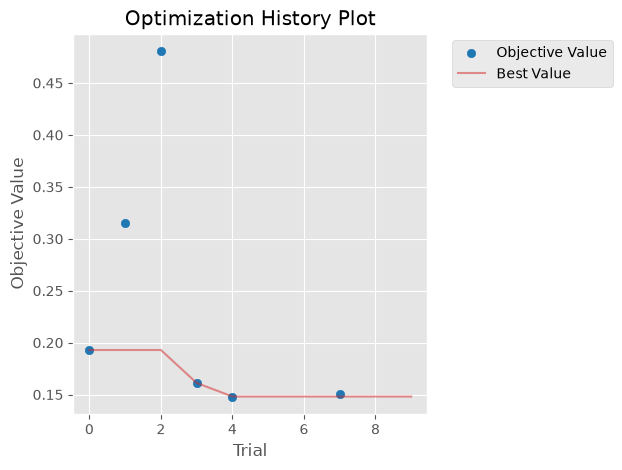

In [13]:
if RUN_HPO and len(study.trials) > 1:
    try:   # which hyperparameters mattered (needs a few completed trials)
        display(pd.Series(optuna.importance.get_param_importances(study), name="importance").round(3))
    except Exception as err:
        print("importance not available:", err)
    optuna.visualization.matplotlib.plot_optimization_history(study); plt.show()

### 5b. Final training
Uses the best search result when `USE_BEST_HPARAMS` is on and `HPO_DIR/best_hparams.json` exists (from this or an
earlier run), otherwise the defaults from the hyperparameter cell. **The number of epochs is always `FINAL_EPOCHS`
(10)**, whatever the search used. Training starts from the pretrained weights on the full training set; the epoch
with the lowest validation KL is restored for the test evaluation.

In [14]:
HPARAMS = dict(lr=LR, weight_decay=WEIGHT_DECAY, warmup_frac=WARMUP_FRAC, grad_accum=GRAD_ACCUM)
HPARAMS_SOURCE = "defaults"
if USE_BEST_HPARAMS and os.path.exists(BEST_HP_PATH):
    HPARAMS.update({k: v for k, v in json.load(open(BEST_HP_PATH))["params"].items() if k != "epochs"})
    HPARAMS_SOURCE = f"Optuna search ({BEST_HP_PATH})"
HPARAMS["epochs"] = FINAL_EPOCHS   # fixed, not taken from the search
LR, WEIGHT_DECAY, WARMUP_FRAC, GRAD_ACCUM, EPOCHS = (HPARAMS[k] for k in
                                                     ("lr", "weight_decay", "warmup_frac", "grad_accum", "epochs"))
print("hyperparameters from", HPARAMS_SOURCE, "->", HPARAMS)

os.makedirs(os.path.dirname(CKPT_PATH), exist_ok=True)
model.load_state_dict(base_state)
t_train = time.time()
history = train_model(model, train_ex, val_ex, **HPARAMS, best_path=CKPT_PATH)
train_minutes = (time.time() - t_train) / 60
empty_cache()
pd.DataFrame(history).round(4)


hyperparameters from Optuna search (hpo/ministral3-3b-reasoning/best_hparams.json) -> {'lr': 3.1335313528540586e-06, 'weight_decay': 0.029214464853521818, 'warmup_frac': 0.07327236865873835, 'grad_accum': 4, 'epochs': 10}


epochs:   0%|          | 0/10 [00:00<?, ?epoch/s]

epoch 1/10:   0%|          | 0/1350 [00:00<?, ?batch/s]

val epoch 1:   0%|          | 0/38 [00:00<?, ?batch/s]

score:   0%|          | 0/600 [00:00<?, ?ex/s]

...

epoch 10/10:   0%|          | 0/1350 [00:00<?, ?batch/s]

val epoch 10:   0%|          | 0/38 [00:00<?, ?batch/s]

score:   0%|          | 0/600 [00:00<?, ?ex/s]

epochs {'epoch': 10.0, 'train_loss': 0.7587, 'val_acc': 0.8, 'val_kl': 0.0873, 'val_brier': 0.0508, 'minutes': 40.7951}


,epoch,train_loss,val_acc,val_kl,val_brier,minutes
0,1,0.9861,0.7450,0.1890,0.0978,41.7284
1,2,0.8611,0.7600,0.1223,0.0684,40.7155
2,3,0.8261,0.8033,0.0967,0.0553,40.4712
3,4,0.8094,0.8083,0.0917,0.0507,41.1820
4,5,0.7967,0.7967,0.0894,0.0528,41.4119
5,6,0.7845,0.8067,0.0816,0.0474,41.2499
6,7,0.7750,0.8100,0.0856,0.0499,40.7089
7,8,0.7668,0.7983,0.0866,0.0505,40.4179
8,9,0.7612,0.8017,0.0865,0.0506,41.2940
9,10,0.7587,0.8000,0.0873,0.0508,40.7951


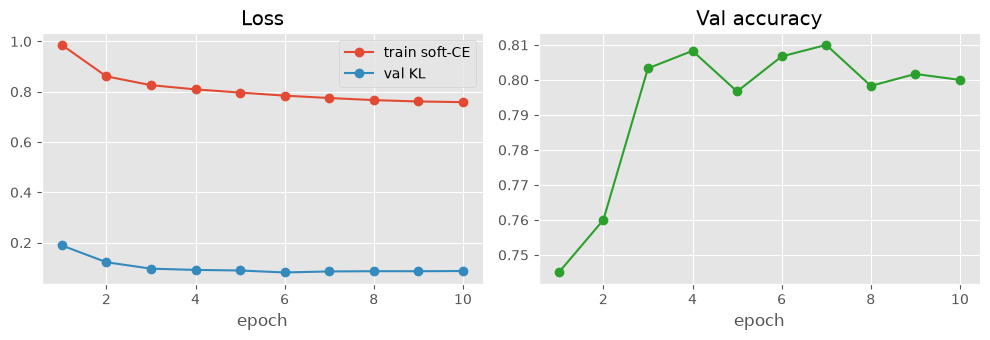

In [15]:
h = pd.DataFrame(history)
curves_fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h.epoch, h.train_loss, marker="o", label="train soft-CE")
ax[0].plot(h.epoch, h.val_kl, marker="o", label="val KL")
ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].plot(h.epoch, h.val_acc, marker="o", color="tab:green")
ax[1].set_xlabel("epoch"); ax[1].set_title("Val accuracy")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 6. Evaluate on the test split

In [16]:
model.load_state_dict(torch.load(CKPT_PATH, map_location="cpu", mmap=True))   # best epoch (lowest val KL)
empty_cache()
t0 = time.time()
ft_preds = predict(model, test_ex, desc="fine-tuned test")
ms_per_case = (time.time() - t0) / len(test_raw) * 1000
print(f"{ms_per_case:.0f} ms per case (5 decisions) on {DEVICE}")
fine_tuned = score(test_ex, ft_preds)
display(score(test_ex, ft_preds, by="qtype"))
display(score(test_ex, ft_preds, by="workflow"))
fine_tuned

fine-tuned test:   0%|          | 0/125 [00:00<?, ?batch/s]

373 ms per case (5 decisions) on cuda


score:   0%|          | 0/2000 [00:00<?, ?ex/s]

score:   0%|          | 0/2000 [00:00<?, ?ex/s]

,accuracy,kl,brier,ece,n
qtype,,,,,
choice,0.8033,0.1035,0.0527,0.2039,600.0
noul,0.8533,0.0390,0.0303,0.1017,600.0
score,0.7788,0.0865,0.0438,0.2070,800.0
OVERALL,0.8085,0.0773,0.0424,0.1742,2000.0


score:   0%|          | 0/2000 [00:00<?, ?ex/s]

,accuracy,kl,brier,ece,n
workflow,,,,,
agent_trace_observability,0.7480,0.0809,0.0486,0.1859,500.0
customer_service,0.8360,0.0862,0.0433,0.1882,500.0
invoice_processing,0.8660,0.0776,0.0420,0.1218,500.0
security_incidents,0.7840,0.0647,0.0359,0.2062,500.0
OVERALL,0.8085,0.0773,0.0424,0.1742,2000.0


,accuracy,kl,brier,ece,n
task,,,,,
agent_trace_observability/action,0.7000,0.0849,0.0436,0.2094,100.0
agent_trace_observability/needs_review,0.8500,0.0454,0.0369,0.1598,100.0
agent_trace_observability/outcome,0.7900,0.1032,0.0599,0.2468,100.0
agent_trace_observability/risk,0.7300,0.0856,0.0547,0.1592,100.0
agent_trace_observability/urgency,0.6700,0.0851,0.0477,0.1747,100.0
customer_service/action,0.7400,0.1556,0.0719,0.2113,100.0
customer_service/category,0.9800,0.0611,0.0232,0.1470,100.0
customer_service/churn_risk,0.8600,0.0824,0.0377,0.2486,100.0
customer_service/needs_human,0.7900,0.0497,0.0427,0.1543,100.0


In [17]:
comparison = pd.DataFrame({
    "Uniform":            score(test_ex, uniform_preds).loc["OVERALL"],
    "Prior":              score(test_ex, prior_preds).loc["OVERALL"],
    "Ministral-3B zero-shot": zero_shot.loc["OVERALL"],
    "Ministral-3B fine-tuned": fine_tuned.loc["OVERALL"],
}).T.drop(columns="n")
comparison

score:   0%|          | 0/2000 [00:00<?, ?ex/s]

score:   0%|          | 0/2000 [00:00<?, ?ex/s]

,accuracy,kl,brier,ece
Uniform,0.2740,0.4445,0.2382,0.0485
Prior,0.4785,0.3274,0.1811,0.0336
Ministral-3B zero-shot,0.3395,1.6588,0.6646,0.5233
Ministral-3B fine-tuned,0.8085,0.0773,0.0424,0.1742


Per-question (`workflow/question`) accuracy, zero-shot vs fine-tuned:

In [18]:
pd.DataFrame({"zero-shot": zero_shot.accuracy, "fine-tuned": fine_tuned.accuracy,
              "Δ": fine_tuned.accuracy - zero_shot.accuracy}).round(3)

,zero-shot,fine-tuned,Δ
task,,,
agent_trace_observability/action,0.31,0.700,0.390
agent_trace_observability/needs_review,0.45,0.850,0.400
agent_trace_observability/outcome,0.07,0.790,0.720
agent_trace_observability/risk,0.34,0.730,0.390
agent_trace_observability/urgency,0.37,0.670,0.300
customer_service/action,0.23,0.740,0.510
customer_service/category,0.83,0.980,0.150
customer_service/churn_risk,0.08,0.860,0.780
customer_service/needs_human,0.67,0.790,0.120


### Inspect a few test predictions

In [19]:
by_case = {}
for e, p in zip(test_ex, ft_preds):
    by_case.setdefault(e["case_id"], []).append((e, p))

for cid in [next(c for c, v in by_case.items() if v[0][0]["workflow"] == w) for w in sorted({e["workflow"] for e in test_ex})]:
    print("=" * 80, "\n", cid)
    for e, p in by_case[cid]:
        fmt = lambda v: ", ".join(f"{l}={x:.2f}" for l, x in zip(e["labels"], v))
        mark = "✓" if e["labels"][int(p.argmax())] == e["gold_label"] else "✗"
        print(f"{mark} {e['task']:<48} pred [{fmt(p)}]\n  {'':<48} gold [{fmt(e['gold_p'])}]")

 agent_trace_observability_000000
✓ agent_trace_observability/action                 pred [continue=0.57, human_review=0.09, observe=0.33, stop=0.01]
                                                   gold [continue=0.58, human_review=0.29, observe=0.09, stop=0.04]
✓ agent_trace_observability/needs_review           pred [true=0.17, false=0.83]
                                                   gold [true=0.36, false=0.64]
✓ agent_trace_observability/outcome                pred [failure=0.03, harmful=0.01, partial=0.10, success=0.86]
                                                   gold [failure=0.07, harmful=0.00, partial=0.32, success=0.61]
✓ agent_trace_observability/risk                   pred [0=0.19, 1=0.70, 2=0.10, 3=0.02]
                                                   gold [0=0.30, 1=0.62, 2=0.08, 3=0.01]
✓ agent_trace_observability/urgency                pred [0=0.51, 1=0.39, 2=0.09, 3=0.01]
                                                   gold [0=0.53, 1=0.38, 2=0.08, 

### 6b. Save this run's summary
Everything needed to compare runs later goes to its own folder under `runs/` (small files, meant to be committed):

| file | contents |
|---|---|
| `summary.json` | config, hyperparameters (and where they came from), data sizes, training curve, test metrics overall / by type / by workflow / by question, baselines |
| `summary.md` | the same as a readable report |
| `train_history.csv`, `training_curves.png` | per-epoch train loss and validation metrics |
| `test_by_task.csv`, `test_by_type.csv`, `test_by_workflow.csv`, `comparison.csv` | test tables (fine-tuned, zero-shot, Uniform, Prior) |
| `test_predictions.jsonl` | the full predicted distributions for every test case |
| `hpo_trials.csv` | the Optuna trials, if the search ran in this session |

`runs/index.csv` is rebuilt from all runs each time. Compare runs in section 10 (the helpers are defined in the next cell, so no extra script is needed).

In [20]:
import glob

def _summaries(runs_dir="runs", pattern=None):
    paths = sorted(glob.glob(os.path.join(pattern or os.path.join(runs_dir, "*"), "summary.json")))
    return [json.load(open(p)) for p in paths]

def load_runs(runs_dir="runs", pattern=None):
    """One row per run with its setup, training result and overall test metrics."""
    rows = []
    for s in _summaries(runs_dir, pattern):
        hp, tr, t = s["hparams"], s["training"], s["test"]["overall"]
        rows.append({
            "run_id": s["run_id"], "created": s["created"], "tag": s.get("tag", ""),
            "model": s["model_id"].split("/")[-1], "config": s["config"], "device": s["device"],
            "hparams_from": "optuna" if s["hparams_source"] != "defaults" else "defaults",
            "lr": hp["lr"], "weight_decay": hp["weight_decay"], "warmup_frac": hp["warmup_frac"],
            "eff_batch": hp["effective_batch"], "epochs": hp["epochs"],
            "best_epoch": tr["best_epoch"], "val_kl": tr["best_val_kl"], "val_acc": tr["best_val_acc"],
            "train_min": tr["minutes"],
            "test_acc": t["accuracy"], "test_kl": t["kl"], "test_brier": t["brier"], "test_ece": t["ece"],
            "ms_per_case": s["test"]["ms_per_case"],
        })
    return pd.DataFrame(rows).set_index("run_id") if rows else pd.DataFrame()

def pretty(runs):
    """Round for display; the learning rate keeps scientific notation instead of rounding to 0."""
    out = runs.round(4)
    if "lr" in out:
        out["lr"] = runs["lr"].map("{:.1e}".format)
    return out

def compare_by(by="type", metric="accuracy", runs_dir="runs", pattern=None):
    """Rows = question types / workflows / questions, columns = runs, values = the chosen test metric."""
    cols = {s["run_id"]: {k: v[metric] for k, v in s["test"][f"by_{by}"].items()}
            for s in _summaries(runs_dir, pattern)}
    return pd.DataFrame(cols)

import subprocess
from datetime import datetime
from huggingface_hub import HfApi

def write_predictions(path):
    """Full test distributions, one line per case, so anyone can re-score."""
    with open(path, "w") as f:
        for cid, items in tqdm(by_case.items(), desc="write predictions", unit="case", leave=False):
            f.write(json.dumps({"id": cid, "workflow": items[0][0]["workflow"], "answers": {
                e["qname"]: {"label": e["labels"][int(p.argmax())],
                             "probabilities": dict(zip(e["labels"], map(float, p)))} for e, p in items}}) + "\n")

def git_info():
    try:
        run = lambda *cmd: subprocess.check_output(["git", *cmd], text=True, stderr=subprocess.DEVNULL).strip()
        commit, dirty = run("rev-parse", "--short", "HEAD"), bool(run("status", "--porcelain"))
        return commit, dirty
    except Exception:
        return None, None

def tables(df):   # DataFrame from score() -> {row: {metric: value}} without the count column
    return df.drop(columns="n").astype(float).round(4).to_dict("index")

# The README's reference rows (Uniform 0.169, Prior 0.088) are close to ECE computed per question and averaged
# over the 20 questions, not pooled over all 2,000 decisions; the leaderboard number uses that, both are kept.
overall = fine_tuned.loc["OVERALL"].copy()
overall["ece_pooled"] = overall.ece
overall["ece"] = fine_tuned.drop("OVERALL").ece.mean()
by_type, by_wf = score(test_ex, ft_preds, by="qtype"), score(test_ex, ft_preds, by="workflow")
try:
    DATASET_SHA = HfApi().dataset_info("LocalLLaMA/typed-decisions").sha
except Exception:
    DATASET_SHA = None

created = datetime.now()
RUN_ID = "_".join(x for x in (created.strftime("%Y%m%d-%H%M%S"), MODEL_ID.split("/")[-1], CONFIG, RUN_TAG) if x)
RUN_DIR = f"{RUNS_DIR}/{RUN_ID}"
os.makedirs(RUN_DIR, exist_ok=True)
commit, dirty = git_info()
best = min(history, key=lambda r: r["val_kl"])

summary = {
    "run_id": RUN_ID, "created": created.isoformat(timespec="seconds"), "tag": RUN_TAG,
    "model_id": MODEL_ID, "config": CONFIG, "dataset_revision": DATASET_SHA,
    "device": DEVICE, "gpu": torch.cuda.get_device_name() if DEVICE == "cuda" else None, "bf16_autocast": AMP, "torch": torch.__version__, "git_commit": commit, "git_dirty": dirty,
    "hparams": {**HPARAMS, "batch_size": BATCH_SIZE, "effective_batch": BATCH_SIZE * HPARAMS["grad_accum"],
                "max_len": MAX_LEN, "val_frac": VAL_FRAC, "seed": SEED, "freeze_embeddings": FREEZE_EMBEDDINGS,
                "gradient_checkpointing": True, "reasoning": "disabled (empty [THINK][/THINK] pre-filled)"},
    "hparams_source": HPARAMS_SOURCE,
    "hpo": ({"n_trials": len(study.trials), "minutes": round(hpo_minutes, 1), "best_val_kl": study.best_value,
             "train_frac": HPO_TRAIN_FRAC} if RUN_HPO and hpo_minutes is not None
            else json.load(open(BEST_HP_PATH)) if HPARAMS_SOURCE != "defaults" else None),
    "data": {"train_cases": len({e["case_id"] for e in train_ex}), "val_cases": len({e["case_id"] for e in val_ex}),
             "test_cases": len(test_raw), "train_decisions": len(train_ex), "val_decisions": len(val_ex),
             "test_decisions": len(test_ex)},
    "training": {"epochs_run": len(history), "best_epoch": best["epoch"], "best_val_kl": float(best["val_kl"]),
                 "best_val_acc": float(best["val_acc"]), "best_val_brier": float(best["val_brier"]),
                 "minutes": round(train_minutes, 1),
                 "history": [{k: round(float(v), 4) for k, v in r.items()} for r in history]},
    "test": {"overall": {k: round(float(overall[k]), 4) for k in ("accuracy", "kl", "brier", "ece", "ece_pooled")},
             "ece_definition": "10-bin max-probability ECE per question, averaged over questions; "
                               "ece_pooled = over all decisions",
             "ms_per_case": round(ms_per_case, 1),
             "by_type": tables(by_type), "by_workflow": tables(by_wf), "by_task": tables(fine_tuned)},
    "baselines": {name: {k: round(float(v), 4) for k, v in row.items()} for name, row in comparison.iterrows()
                  if "fine-tuned" not in name},
}
json.dump(summary, open(f"{RUN_DIR}/summary.json", "w"), indent=1)

pd.DataFrame(history).round(4).to_csv(f"{RUN_DIR}/train_history.csv", index=False)
curves_fig.savefig(f"{RUN_DIR}/training_curves.png", dpi=120, bbox_inches="tight")
fine_tuned.to_csv(f"{RUN_DIR}/test_by_task.csv")
by_type.to_csv(f"{RUN_DIR}/test_by_type.csv")
by_wf.to_csv(f"{RUN_DIR}/test_by_workflow.csv")
comparison.round(4).to_csv(f"{RUN_DIR}/comparison.csv")
write_predictions(f"{RUN_DIR}/test_predictions.jsonl")
if RUN_HPO and hpo_minutes is not None:
    study.trials_dataframe().to_csv(f"{RUN_DIR}/hpo_trials.csv", index=False)

o = summary["test"]["overall"]
report = f"""# Run `{RUN_ID}`

* **Model:** `{MODEL_ID}` (Specialist) on `{CONFIG}` | device `{DEVICE}` | git `{commit or "n/a"}`{" (uncommitted changes)" if dirty else ""}
* **Hyperparameters** ({HPARAMS_SOURCE}): lr {HPARAMS['lr']:.2e}, weight decay {HPARAMS['weight_decay']:.3f},
  warmup {HPARAMS['warmup_frac']:.2f}, effective batch {BATCH_SIZE * HPARAMS['grad_accum']}, {HPARAMS['epochs']} epochs
* **Training:** {train_minutes:.1f} min, best epoch {best['epoch']} (val KL {best['val_kl']:.4f}, val acc {best['val_acc']:.3f})
* **Test:** accuracy **{o['accuracy']:.3f}**, KL **{o['kl']:.4f}**, Brier {o['brier']:.4f}, ECE {o['ece']:.4f}
  (pooled {o['ece_pooled']:.4f}), {ms_per_case:.0f} ms / case

## Training curve

{pd.DataFrame(history).round(4).to_markdown(index=False)}

## Test vs baselines

{comparison.round(4).to_markdown()}

## By question type

{by_type.round(4).to_markdown()}

## By workflow

{by_wf.round(4).to_markdown()}

## By question

{fine_tuned.round(4).to_markdown()}
"""
open(f"{RUN_DIR}/summary.md", "w").write(report)

load_runs(RUNS_DIR).to_csv(f"{RUNS_DIR}/index.csv")
print("saved run to", RUN_DIR)
print(sorted(os.listdir(RUN_DIR)))

score:   0%|          | 0/2000 [00:00<?, ?ex/s]

score:   0%|          | 0/2000 [00:00<?, ?ex/s]

write predictions:   0%|          | 0/400 [00:00<?, ?case/s]

saved run to runs/20261013-180321_Ministral-3-3B-Reasoning-2512_all
['comparison.csv', 'hpo_trials.csv', 'summary.json', 'summary.md', 'test_by_task.csv', 'test_by_type.csv', 'test_by_workflow.csv', 'test_predictions.jsonl', 'train_history.csv', 'training_curves.png']


## 7. Save the model and an inference helper

In [21]:
# saved in bf16 (the base model's dtype): half the size of the fp32 training weights
model.to(torch.bfloat16)
model.config.use_cache = True
model.save_pretrained(OUT_DIR)
tok.save_pretrained(OUT_DIR)
json.dump({"letters": LETTERS, "letter_ids": LETTER_IDS, "system": SYSTEM, "assistant_prefix": NO_THINK},
          open(f"{OUT_DIR}/decider_config.json", "w"))
print("saved to", OUT_DIR)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved to ministral3-3b-reasoning-typed-decisions


In [22]:
@torch.no_grad()
def decide(state: dict, questions: dict) -> dict:
    """Answer a typed-decisions request: returns {question: {label, confidence, probabilities}}."""
    exs = []
    for qname, q in questions.items():
        labels = [l for l, _ in question_options(q)]
        exs.append(dict(qname=qname, labels=labels, gold_p=np.zeros(len(labels), np.float32),
                        input_ids=tok(to_chat(build_prompt(state, qname, q)), add_special_tokens=False)["input_ids"][:MAX_LEN]))
    out = {}
    for e, p in zip(exs, predict(model, exs)):
        probs = dict(zip(e["labels"], map(float, p)))
        out[e["qname"]] = dict(label=e["labels"][int(p.argmax())], confidence=float(p.max()), probabilities=probs)
    return out

def show(result):
    """Pretty-print the output of decide()."""
    for qname, r in result.items():
        probs = "  ".join(f"{l}={p:.2f}" for l, p in r["probabilities"].items())
        print(f"{qname:<22} -> {r['label']:<14} ({r['confidence']:.0%})   [{probs}]")

r = test_raw[0]
print(r["workflow"])
show(decide(json.loads(r["state"]), json.loads(r["questions"])))

agent_trace_observability
action                 -> continue       (59%)   [continue=0.59  human_review=0.08  observe=0.31  stop=0.01]
needs_review           -> false          (83%)   [true=0.17  false=0.83]
outcome                -> success        (86%)   [failure=0.03  harmful=0.01  partial=0.10  success=0.86]
risk                   -> 1              (69%)   [0=0.19  1=0.69  2=0.10  3=0.02]
urgency                -> 0              (51%)   [0=0.51  1=0.40  2=0.08  3=0.01]


## 8. Try it yourself
Reload the saved model from disk (so this section also works in a fresh session once sections 1–3 have run
and the helper cells above are defined), then run it on hand-written invoices. The five standard invoice questions
are taken from the dataset; edit `my_state` below, or paste any case JSON (from any workflow, with its questions),
to test your own input.

In [23]:
model = Ministral3ForCausalLM.from_pretrained(OUT_DIR, dtype=torch.bfloat16).to(DEVICE).eval()
tok = AutoTokenizer.from_pretrained(OUT_DIR, fix_mistral_regex=True)

QUESTIONS = json.loads(next(r for r in test_raw if r["workflow"] == "invoice_processing")["questions"])
print(list(QUESTIONS))


Loading weights:   0%|          | 0/236 [00:00<?, ?it/s]

['discrepancy_severity', 'disposition', 'duplicate', 'matches_order', 'urgency']


### Built-in examples

In [24]:
def make_state(inv_id="INV-2026-5001", vendor="Acme Supplies", inv_qty=10, inv_unit=50.0,
               po_qty=10, po_unit=50.0, received_qty=10, condition="accepted",
               days_until_due=20, status="unpaid", prior_ids=(), disputes=0,
               discount_pct=None, discount_days=None):
    """Build a case in the dataset's schema from a few knobs (single line item)."""
    return {
        "invoice": {"id": inv_id, "vendor": vendor, "currency": "USD",
                    "lines": [{"sku": "SKU-100", "qty": inv_qty, "unit_usd": inv_unit,
                               "total_usd": round(inv_qty * inv_unit, 2)}],
                    "total_usd": round(inv_qty * inv_unit, 2)},
        "purchase_order": {"id": "PO-9001", "lines": [{"qty": po_qty, "unit_usd": po_unit}],
                           "total_usd": round(po_qty * po_unit, 2),
                           "freight_terms": "freight prepaid by vendor, not separately billable"},
        "delivery": {"date": "2026-03-01", "received_qty": received_qty, "condition": condition},
        "payment": {"terms": "net 30", "status": status, "days_until_due": days_until_due,
                    "early_payment_discount_pct": discount_pct, "discount_expires_in_days": discount_days},
        "vendor_history": {"invoices_12m": 12, "disputes_12m": disputes, "prior_invoice_ids": list(prior_ids)},
    }

examples = {
    "clean match":            make_state(),
    "duplicate invoice":      make_state(inv_id="INV-2026-4242", prior_ids=["INV-2026-4242", "INV-2026-3100"]),
    "over-billed price":      make_state(inv_unit=65.0),
    "short delivery":         make_state(received_qty=6),
    "overdue, discount soon": make_state(days_until_due=-5, status="overdue", discount_pct=2, discount_days=1),
}
for name, st in tqdm(examples.items(), desc="examples", unit="case"):
    print(f"\n=== {name}")
    show(decide(st, QUESTIONS))

examples:   0%|          | 0/5 [00:00<?, ?case/s]


=== clean match
discrepancy_severity   -> 0              (99%)   [0=0.99  1=0.01  2=0.00  3=0.00]
disposition            -> approve        (83%)   [approve=0.83  hold=0.13  manual_review=0.04  reject=0.00]
duplicate              -> false          (97%)   [true=0.03  false=0.97]
matches_order          -> true           (99%)   [true=0.99  false=0.01]
urgency                -> 1              (75%)   [0=0.10  1=0.75  2=0.13  3=0.01]

=== duplicate invoice
discrepancy_severity   -> 0              (87%)   [0=0.87  1=0.03  2=0.01  3=0.09]
disposition            -> approve        (60%)   [approve=0.60  hold=0.14  manual_review=0.07  reject=0.19]
duplicate              -> false          (56%)   [true=0.44  false=0.56]
matches_order          -> true           (97%)   [true=0.97  false=0.03]
urgency                -> 1              (75%)   [0=0.11  1=0.75  2=0.12  3=0.02]

=== over-billed price
discrepancy_severity   -> 3              (78%)   [0=0.00  1=0.01  2=0.20  3=0.78]
disposition        

### Your input
Edit the dict below (any fields in the dataset schema) and re-run the cell.
You can also pass a subset of questions, or write your own question in the same typed format.

In [25]:
my_state = {
    "invoice": {"id": "INV-2026-7777", "vendor": "Northwind Traders", "currency": "USD",
                "lines": [{"sku": "SKU-210", "qty": 20, "unit_usd": 12.5, "total_usd": 250.0},
                          {"sku": "FREIGHT", "qty": 1, "unit_usd": 45.0, "total_usd": 45.0}],
                "total_usd": 295.0},
    "purchase_order": {"id": "PO-3141", "lines": [{"qty": 20, "unit_usd": 12.5}], "total_usd": 250.0,
                       "freight_terms": "freight prepaid by vendor, not separately billable"},
    "delivery": {"date": "2026-10-01", "received_qty": 20, "condition": "accepted"},
    "payment": {"terms": "net 30", "status": "unpaid", "days_until_due": 3,
                "early_payment_discount_pct": None, "discount_expires_in_days": None},
    "vendor_history": {"invoices_12m": 30, "disputes_12m": 1, "prior_invoice_ids": ["INV-2026-7001"]},
}

show(decide(my_state, QUESTIONS))

discrepancy_severity   -> 3              (54%)   [0=0.01  1=0.03  2=0.42  3=0.54]
disposition            -> manual_review  (67%)   [approve=0.02  hold=0.23  manual_review=0.67  reject=0.08]
duplicate              -> false          (97%)   [true=0.03  false=0.97]
matches_order          -> false          (97%)   [true=0.03  false=0.97]
urgency                -> 2              (64%)   [0=0.01  1=0.16  2=0.64  3=0.18]


In [26]:
# Or paste a case as JSON text (e.g. a row's `state` copied from the dataset) ...
my_json = """
PASTE_CASE_JSON_HERE
"""
my_json_questions = QUESTIONS   # for another workflow, paste that row's `questions` here as a dict
if "PASTE" not in my_json:
    show(decide(json.loads(my_json), my_json_questions))

# ... and/or ask a custom question (types: "choice" with a criteria dict, "noul" true/false, "score" with a list)
my_questions = {
    "needs_vendor_contact": {"type": "noul",
                             "instructions": "Someone should contact the vendor before this invoice is paid.",
                             "criteria": {"true": "The vendor must clarify or correct something.",
                                          "false": "No vendor contact is needed."}},
}
show(decide(my_state, my_questions))

needs_vendor_contact   -> true           (70%)   [true=0.70  false=0.30]


## 9. Publish to the Hugging Face Hub (leaderboard)
The benchmark is a Hub **Benchmark** dataset (it ships an `eval.yaml` with tasks `accuracy`, `kl_from_gold`, `brier`
and `ece` on `all/test`). A model repo that contains `.eval_results/*.yaml` with those task ids is picked up by the
dataset's leaderboard automatically. The README tables are curated by hand, so the dataset card also asks you to
open a discussion with the numbers and the mode; the last cell does that.

This model was fine-tuned on `train`, so it belongs to the **"Fitted or fine-tuned on `train`"** table, and it
is labelled a **(Specialist)** model (trained for this benchmark only) in the model card, the results row and
the submission title.
Format follows the [Hub eval-results docs](https://huggingface.co/docs/hub/en/eval-results): one entry per task id,
values as fractions (as other entries on this leaderboard do), the dataset revision we scored against, and a
`source` link to the full test predictions in the model repo.
Nothing is uploaded until you flip the flags below. Needs a token with write access (`uv run hf auth login`).

In [27]:
import os
from datetime import date
from huggingface_hub import HfApi, whoami

BENCHMARK       = "LocalLLaMA/typed-decisions"
HF_REPO         = f"{whoami()['name']}/{os.path.basename(OUT_DIR)}"
PRIVATE         = False   # the leaderboard only lists public models
PUSH_TO_HUB     = True   # set True to create/update the model repo with weights, model card and eval results
OPEN_DISCUSSION = True   # set True to post the scores on the benchmark's discussion board

api = HfApi()
DATASET_SHA = DATASET_SHA or api.dataset_info(BENCHMARK).sha
# overall (leaderboard ECE convention), by_type and by_wf come from section 6b
print(HF_REPO, "| dataset revision", DATASET_SHA[:8])
overall

rony/ministral3-3b-reasoning-typed-decisions | dataset revision c806f6c6


accuracy         0.808500
kl               0.077300
brier            0.042400
ece              0.182195
n             2000.000000
ece_pooled       0.174200
Name: OVERALL, dtype: float64

Write the predictions, metrics, `.eval_results/` file and model card into `OUT_DIR` (next to the saved weights).

In [34]:
import yaml

write_predictions(f"{OUT_DIR}/test_predictions.jsonl")

metrics = {"config": CONFIG, "split": "test", "n_cases": len(test_raw), "n_decisions": len(test_ex),
           "overall": overall.drop("n").to_dict(), "ece_definition": "10-bin max-probability ECE per question, averaged over questions; ece_pooled = over all decisions", "by_type": by_type.drop(columns="n").to_dict("index"),
           "by_workflow": by_wf.drop(columns="n").to_dict("index"), "ms_per_case": ms_per_case, "device": DEVICE}
json.dump(metrics, open(f"{OUT_DIR}/test_metrics.json", "w"), indent=1)

# Hub eval results -> benchmark leaderboard
os.makedirs(f"{OUT_DIR}/.eval_results", exist_ok=True)
NOTES = (f"(Specialist) Fine-tuned on the Typed Decisions train split ({MODEL_ID}, full fine-tune, reasoning "
         "disabled via an empty [THINK][/THINK] block) - NOT zero-shot; belongs to the "
         f"'fitted or fine-tuned on train' table. Test split, {len(test_raw)} cases / {len(test_ex)} decisions. "
         "One forward pass per question (not all five in one request); distribution = softmax over the option-letter "
         "logits. ECE = 10-bin max-probability ECE per question, averaged over the 20 questions "
         f"(pooled over all decisions: {overall.ece_pooled:.4f}). Self-reported, no verifyToken.")
SOURCE = {"url": f"https://huggingface.co/{HF_REPO}/blob/main/test_predictions.jsonl",
          "name": "Full test distributions", "user": HF_REPO.split("/")[0]}
eval_results = [{"dataset": {"id": BENCHMARK, "task_id": task, "revision": DATASET_SHA},
                 "value": round(float(overall[col]), 4), "date": date.today().isoformat(),
                 "source": dict(SOURCE), "notes": NOTES}   # copies: no YAML anchors/aliases
                for task, col in [("accuracy", "accuracy"), ("kl_from_gold", "kl"), ("brier", "brier"), ("ece", "ece")]]
yaml.safe_dump(eval_results, open(f"{OUT_DIR}/.eval_results/typed-decisions.yaml", "w"), sort_keys=False)

def md_table(df):
    df = df.drop(columns="n", errors="ignore")
    head = "| | " + " | ".join(df.columns) + " |\n|---|" + "---|" * len(df.columns) + "\n"
    return head + "\n".join(f"| {i} | " + " | ".join(f"{v:.3f}" for v in r) + " |" for i, r in df.iterrows())

RESULTS_MD = (f"Scored on `{BENCHMARK}` `all/test` ({len(test_raw)} cases, {len(test_ex)} decisions), "
              f"never seen in training.\n\n"
              f"| Model | Kind | Accuracy ↑ | KL from gold ↓ | Brier ↓ | ECE ↓ | Latency |\n|---|---|---|---|---|---|---|\n"
              f"| [{HF_REPO.split('/')[-1]}](httpuv run jupyter lab ministral3_3b_reasoning_decisions.ipynbs://huggingface.co/{HF_REPO}) (Specialist; Ministral 3 3B Reasoning, full fine-tune) | "
              f"fine-tuned on `train` | {overall.accuracy:.3f} | {overall.kl:.4f} | {overall.brier:.4f} | {overall.ece:.4f} | "
              f"{ms_per_case:.0f} ms / case ({torch.cuda.get_device_name() if DEVICE == 'cuda' else DEVICE}) |\n\n"
              f"ECE is computed per question and averaged over the 20 questions (closest to the README's reference rows); "
              f"pooled over all decisions it is {overall.ece_pooled:.4f}.\n\n"
              f"**By question type**\n\n{md_table(by_type)}\n\n**By workflow**\n\n{md_table(by_wf)}\n\n"
              f"Baselines on the same split: Prior accuracy {comparison.loc['Prior', 'accuracy']:.3f} / "
              f"KL {comparison.loc['Prior', 'kl']:.3f}; zero-shot Ministral 3 3B Reasoning accuracy "
              f"{comparison.loc['Ministral-3B zero-shot', 'accuracy']:.3f} / KL {comparison.loc['Ministral-3B zero-shot', 'kl']:.3f}.")

CARD = f"""---
base_model: {MODEL_ID}
datasets:
- {BENCHMARK}
license: apache-2.0
library_name: transformers
tags:
- typed-decisions
- specialist
- calibration
- structured-decisions
- probabilistic-classification
---

# {HF_REPO.split('/')[-1]} (Specialist)

**Specialist model:** fine-tuned for the Typed Decisions benchmark only; it is not a general-purpose chat or
reasoning model.

[Ministral 3 3B Reasoning]({"https://huggingface.co/" + MODEL_ID}) fully fine-tuned (text decoder only; vision tower
dropped, input embedding / tied LM head frozen) as a **probabilistic decision model** for
[{BENCHMARK}](https://huggingface.co/datasets/{BENCHMARK}). Mode: **fine-tuned on `train`** (all four workflows,
{len(train_ex) // 5} cases for training and {len(val_ex) // 5} held out for epoch selection on validation KL).

## Results

{RESULTS_MD}

Full test distributions: `test_predictions.jsonl`; metrics: `test_metrics.json`.
Gold is the mean of three teacher samples, so scores measure agreement with that teacher (self-agreement ≈ 0.735).

## How it works

Each (case, question) pair is one prompt: a short system turn, then the case JSON, the question's instructions,
and its options listed as letters `A`, `B`, `C`, … with their descriptions. The assistant turn is pre-filled with an
empty `[THINK][/THINK]` block, so no reasoning is generated: the next-token logits at that position, restricted to
those letter tokens and softmaxed, are the answer distribution. Training minimises soft cross-entropy against the
gold distribution. One forward pass per question (5 per case).

## Usage

```python
import json, torch
from transformers import AutoTokenizer, AutoModelForCausalLM

repo = "{HF_REPO}"
tok = AutoTokenizer.from_pretrained(repo, fix_mistral_regex=True)
model = AutoModelForCausalLM.from_pretrained(repo, dtype=torch.bfloat16).eval()
LETTERS = "ABCDEFGHIJ"
SYSTEM = {SYSTEM!r}
uv run jupyter lab ministral3_3b_reasoning_decisions.ipynb
def options(q):
    if q["type"] == "choice": return list(q["criteria"].items())
    if q["type"] == "noul":
        c = q.get("criteria") or {{}}
        return [("true", c.get("true", "The statement is true.")), ("false", c.get("false", "The statement is false."))]
    return [(str(i), d) for i, d in enumerate(q["criteria"])]

@torch.no_grad()
def decide(state, questions):
    out = {{}}
    for name, q in questions.items():
        opts = options(q)
        kind = {{"choice": "Choose one option.", "noul": "Is the statement true or false?",
                "score": "Pick the level on the rubric."}}[q["type"]]
        prompt = (f"### Case\\n{{json.dumps(state, separators=(',', ':'))}}\\n\\n"
                  f"### Question ({{name}})\\n{{q['instructions']}}\\n{{kind}}\\n\\n### Options\\n"
                  + "\\n".join(f"{{LETTERS[i]}}. {{l}}: {{d}}" for i, (l, d) in enumerate(opts))
                  + "\\n\\nAnswer with one letter.")
        text = tok.apply_chat_template([{{"role": "system", "content": SYSTEM}}, {{"role": "user", "content": prompt}}],
                                       tokenize=False, add_generation_prompt=True) + "[THINK][/THINK]"
        logits = model(**tok(text, add_special_tokens=False, return_tensors="pt")).logits[0, -1]
        ids = [tok.encode(LETTERS[i], add_special_tokens=False)[0] for i in range(len(opts))]
        p = torch.softmax(logits[ids].float(), -1).tolist()
        out[name] = dict(zip([l for l, _ in opts], p))
    return out
```
"""
open(f"{OUT_DIR}/README.md", "w").write(CARD)
print(open(f"{OUT_DIR}/.eval_results/typed-decisions.yaml").read())
print(RESULTS_MD)

write predictions:   0%|          | 0/400 [00:00<?, ?case/s]

- dataset:
    id: LocalLLaMA/typed-decisions
    task_id: accuracy
    revision: c806f6c69d734f29436f25536138547031a673d6
  value: 0.8085
  date: '2026-10-13'
  source:
    url: https://huggingface.co/rony/ministral3-3b-reasoning-typed-decisions/blob/main/test_predictions.jsonl
    name: Full test distributions
    user: rony
  notes: '(Specialist) Fine-tuned on the Typed Decisions train split (mistralai/Ministral-3-3B-Reasoning-2512,
    full fine-tune, reasoning disabled via an empty [THINK][/THINK] block) - NOT zero-shot;
    belongs to the ''fitted or fine-tuned on train'' table. Test split, 400 cases
    / 2000 decisions. One forward pass per question (not all five in one request);
    distribution = softmax over the option-letter logits. ECE = 10-bin max-probability
    ECE per question, averaged over the 20 questions (pooled over all decisions: 0.1742).
    Self-reported, no verifyToken.'
- dataset:
    id: LocalLLaMA/typed-decisions
    task_id: kl_from_gold
    revision: c806

In [35]:
if PUSH_TO_HUB:
    api.create_repo(HF_REPO, private=PRIVATE, exist_ok=True)
    api.upload_folder(folder_path=OUT_DIR, repo_id=HF_REPO,
                      commit_message=f"Ministral 3 3B Reasoning (Specialist) typed-decisions: acc {overall.accuracy:.3f}, KL {overall.kl:.4f}")
    print("pushed: https://huggingface.co/" + HF_REPO)
    # the benchmark's leaderboard API should list the model (per task) shortly after the push
    import requests
    for task in ("accuracy", "kl_from_gold"):
        lb = requests.get(f"https://huggingface.co/api/datasets/{BENCHMARK}/leaderboard", params={"task_id": task}).json()
        hit = [r for r in lb if r.get("modelId") == HF_REPO]
        print(task, "->", f"rank {hit[0]['rank']}, value {hit[0]['value']}" if hit else "not listed yet (can take a few minutes)")
else:
    print("PUSH_TO_HUB is False; nothing uploaded")

pushed: https://huggingface.co/rony/ministral3-3b-reasoning-typed-decisions
accuracy -> not listed yet (can take a few minutes)
kl_from_gold -> not listed yet (can take a few minutes)


In [36]:
DISCUSSION = f"""**Model:** https://huggingface.co/{HF_REPO}
**Mode:** (Specialist) fine-tuned on `train` (all four workflows), for the "Fitted or fine-tuned on `train`" table.

{RESULTS_MD}

**Setup.** Full fine-tune of the text decoder of `{MODEL_ID}` (vision tower dropped, tied embedding / LM head
frozen, reasoning disabled with an empty `[THINK][/THINK]` block; AdamW, lr {LR:.2e}, weight decay {WEIGHT_DECAY:.3f}, warmup {WARMUP_FRAC:.2f},
effective batch {BATCH_SIZE * GRAD_ACCUM}, {EPOCHS} epochs; hyperparameters from {HPARAMS_SOURCE}; epoch picked on
held-out-train KL).
Each question is its own forward pass (5 per case, not all five in one request); the answer distribution is the softmax
of the next-token logits over the option letters. ECE is 10-bin expected calibration error of max probability vs.
correctness. Full test distributions are in `test_predictions.jsonl` in the model repo, so the numbers can be re-run.
"""
print(DISCUSSION)

if OPEN_DISCUSSION:
    d = api.create_discussion(BENCHMARK, repo_type="dataset",
                              title=f"Submission: {HF_REPO} (Specialist) (Ministral 3 3B Reasoning, fine-tuned on train)", description=DISCUSSION)
    print("opened:", d.url)

**Model:** https://huggingface.co/rony/ministral3-3b-reasoning-typed-decisions
**Mode:** (Specialist) fine-tuned on `train` (all four workflows), for the "Fitted or fine-tuned on `train`" table.

Scored on `LocalLLaMA/typed-decisions` `all/test` (400 cases, 2000 decisions), never seen in training.

| Model | Kind | Accuracy ↑ | KL from gold ↓ | Brier ↓ | ECE ↓ | Latency |
|---|---|---|---|---|---|---|
| [ministral3-3b-reasoning-typed-decisions](httpuv run jupyter lab ministral3_3b_reasoning_decisions.ipynbs://huggingface.co/rony/ministral3-3b-reasoning-typed-decisions) (Specialist; Ministral 3 3B Reasoning, full fine-tune) | fine-tuned on `train` | 0.808 | 0.0773 | 0.0424 | 0.1822 | 373 ms / case (NVIDIA GB10) |

ECE is computed per question and averaged over the 20 questions (closest to the README's reference rows); pooled over all decisions it is 0.1742.

**By question type**

| | accuracy | kl | brier | ece |
|---|---|---|---|---|
| choice | 0.803 | 0.103 | 0.053 | 0.204 |
| noul | 

## 10. Compare runs
Every run saved in section 6b is listed here (newest first), so changes in model, hyperparameters or code can be
compared side by side. Runs of all models (Gemma, Ministral, …) share `runs/`, so they show up side by side.

In [37]:
runs = load_runs(RUNS_DIR)
display(pretty(runs.sort_values("created", ascending=False)))

,created,tag,model,config,device,hparams_from,lr,weight_decay,warmup_frac,eff_batch,epochs,best_epoch,val_kl,val_acc,train_min,test_acc,test_kl,test_brier,test_ece,ms_per_case
run_id,,,,,,,,,,,,,,,,,,,,
20261013-180321_Ministral-3-3B-Reasoning-2512_all,2026-10-13T18:03:21,,Ministral-3-3B-Reasoning-2512,all,cuda,optuna,3.1e-06,0.0292,0.0733,16,10,6,0.0816,0.8067,415.6,0.8085,0.0773,0.0424,0.1822,373.3
20261012-214608_gemma-3-270m-it_all,2026-10-12T21:46:08,,gemma-3-270m-it,all,cuda,optuna,3.0e-05,0.0100,0.1000,16,12,12,0.1409,0.7467,67.4,0.7615,0.1319,0.0716,0.1480,67.5
20261012-200609_gemma-3-270m-it_all,2026-10-12T20:06:09,,gemma-3-270m-it,all,cuda,optuna,3.0e-05,0.0100,0.1000,16,4,4,0.1710,0.7033,22.4,0.7015,0.1555,0.0914,0.1282,68.0
20261012-183539_gemma-3-270m-it_all,2026-10-12T18:35:39,,gemma-3-270m-it,all,cuda,optuna,3.0e-05,0.0100,0.1000,16,4,4,0.1710,0.7033,24.9,0.7015,0.1555,0.0914,0.1282,74.7


In [38]:
# break the test metrics down per question type / workflow / question; one column per run
display(compare_by("type", "accuracy", RUNS_DIR).round(3))
display(compare_by("workflow", "kl", RUNS_DIR).round(4))

,20261012-183539_gemma-3-270m-it_all,20261012-200609_gemma-3-270m-it_all,20261012-214608_gemma-3-270m-it_all,20261013-180321_Ministral-3-3B-Reasoning-2512_all
choice,0.635,0.635,0.732,0.803
noul,0.770,0.770,0.822,0.853
score,0.700,0.700,0.739,0.779
OVERALL,0.702,0.702,0.762,0.808


,20261012-183539_gemma-3-270m-it_all,20261012-200609_gemma-3-270m-it_all,20261012-214608_gemma-3-270m-it_all,20261013-180321_Ministral-3-3B-Reasoning-2512_all
agent_trace_observability,0.1168,0.1168,0.0953,0.0809
customer_service,0.1286,0.1286,0.1335,0.0862
invoice_processing,0.2908,0.2908,0.2175,0.0776
security_incidents,0.0859,0.0859,0.0814,0.0647
OVERALL,0.1555,0.1555,0.1319,0.0773


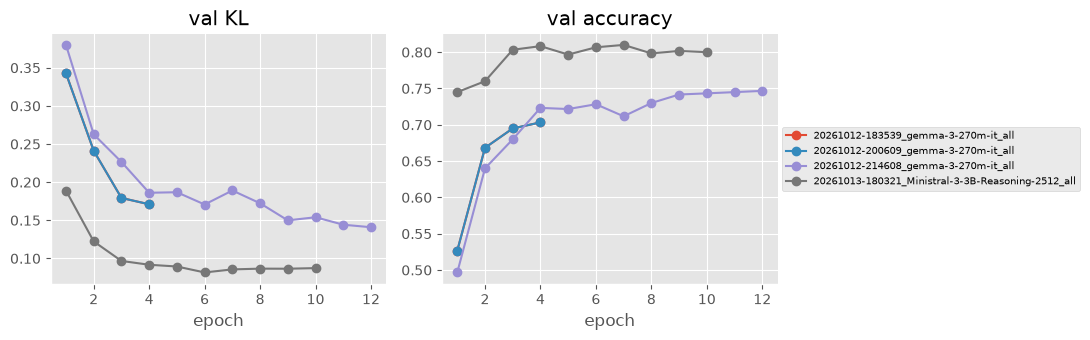

In [39]:
# training curves of all runs (validation KL per epoch)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for run_id in runs.index:
    h = pd.read_csv(f"{RUNS_DIR}/{run_id}/train_history.csv")
    ax[0].plot(h.epoch, h.val_kl, marker="o", label=run_id)
    ax[1].plot(h.epoch, h.val_acc, marker="o", label=run_id)
ax[0].set_title("val KL"); ax[1].set_title("val accuracy")
for a in ax: a.set_xlabel("epoch"); a.spines[["top", "right"]].set_visible(False)
ax[1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()

## Notes
* **Reading the score.** Gold is the average of three teacher samples; the dataset card puts teacher self-agreement at
  ~0.735 accuracy, so scores far above that mean the model is fitting teacher quirks.
* The leaderboard sends all five questions in one request; this notebook asks one question per forward pass
  (5 passes per case), which is the natural shape for a classifier-style fine-tune. Say so when submitting.
* Reasoning is switched off (empty `[THINK][/THINK]`): the model answers in one forward pass. Letting it reason first
  would need generation and parsing, and a distribution over the final letter after the trace.
* 1,080 training cases are used (120 held out for epoch selection). With `FINAL_EPOCHS` fixed you can also set
  `VAL_FRAC = 0` to train on all 1,200 (the best-epoch logic then needs a val set, so keep the last epoch instead).
* Memory: if the final run runs out of memory, set `BATCH_SIZE = 2, GRAD_ACCUM = 8` (same effective batch).
* `checkpoints/` holds the best epoch's fp32 weights (~14 GB); delete it once the model is saved/pushed.
* To trade calibration for accuracy, select epochs on `val_acc` instead of `val_kl`.